# Revision analyses — Child marriage trajectory paper (IJEqH)

Response-to-reviewers analyses. Converted from `revision_analyses.py`.

```
Revision analyses — Child marriage trajectory paper (IJEqH), response to reviewers.

Re-uses the loaders, country summary and classification rules from
Child_Marriage_Analysis_Revised.ipynb unchanged, and adds:

  R1a  Data-structure audit (observations per series, spacing, number of
       contributing surveys, latest survey year)
  R1b  AAPC estimator comparison: primary (full-period linear slope / mean),
       log-linear APC, and endpoint (first/last point) compound rate;
       classification agreement (Cohen's kappa)
  R1c  Low-prevalence category (all six data points < 5%)
  R1d  Monte Carlo simulation of rounding (U[-0.5, 0.5]) and sampling error
       (binomial SE under assumed effective cohort sample sizes); per-country
       classification stability and 95% uncertainty intervals for AAPC
  R1e  Survey-date endogeneity: latest survey year by trajectory group
  R2   CMMM-derived predictors: crude ORs with 95% CI (bug in the original
       cell fixed), Benjamini–Hochberg adjustment
  H5   Inequality gradients: medians, Kruskal–Wallis, Dunn post-hoc (Holm),
       and OLS adjustment for current national prevalence
  Supplementary Table S1 (by category) written as LaTeX.

Usage:  python revision_analyses.py   (expects the two CMMM xlsx files in BASE_DIR)
```

**Before running:** set `BASE_DIR` (cell below) to the folder containing the two CMMM `.xlsx` files. Outputs (figures, `Master_results_revision.csv`, `revision_results.json`, `tableS1_rows.tex`) are written to `BASE_DIR/revision_outputs`.

## 0. Imports and configuration

In [1]:
import os, json, re, warnings
import numpy as np, pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import cohen_kappa_score
import statsmodels.api as sm
import statsmodels.formula.api as smf
warnings.filterwarnings("ignore")

BASE_DIR = os.environ.get("CM_BASE_DIR", r"C:\Users\ningthoujama\Desktop\NewResearchandProject\Child_Marriage")
OUT = os.environ.get("CM_OUT_DIR", os.path.join(BASE_DIR, "revision_outputs"))
os.makedirs(OUT, exist_ok=True)
TRENDS_FILE = os.path.join(BASE_DIR, "2025_06_30_CMMM_trends_cd2deed277_fb7fd8b2f4.xlsx")
PREV_FILE = os.path.join(BASE_DIR, "2025_06_30_CMMM_prevalence_80599aadfe_05da3141d2.xlsx")
TRAJ_ORDER = ['Fast Decline', 'Slow Decline', 'Stagnation', 'Reversal']
PALETTE = {'Fast Decline': '#1a7744', 'Slow Decline': '#4ea8de',
           'Stagnation': '#f4a261', 'Reversal': '#e63946'}
R = {}  # all reported numbers

## 1. Data loaders, AAPC and classification rules
Same logic as `Child_Marriage_Analysis_Revised.ipynb`.

In [2]:
# ───────────────────────── loaders (verbatim logic from notebook) ─────────────
import zipfile, xml.etree.ElementTree as ET
def _read_xlsx_rows(path):
    ns = {'s': 'http://schemas.openxmlformats.org/spreadsheetml/2006/main'}
    with zipfile.ZipFile(path) as z:
        shared = []
        if 'xl/sharedStrings.xml' in z.namelist():
            tree = ET.parse(z.open('xl/sharedStrings.xml'))
            for si in tree.findall('.//s:si', ns):
                shared.append(''.join(t.text or '' for t in si.findall('.//s:t', ns)))
        sheets = sorted([n for n in z.namelist()
                         if n.startswith('xl/worksheets/sheet') and n.endswith('.xml')])
        rows_all = []
        for sheet in sheets[:1]:
            tree = ET.parse(z.open(sheet))
            for row in tree.findall('.//s:row', ns):
                r = []
                for c in row.findall('s:c', ns):
                    t = c.get('t', ''); v_el = c.find('s:v', ns)
                    if v_el is None: r.append(np.nan)
                    elif t == 's': r.append(shared[int(v_el.text)])
                    else:
                        try: r.append(float(v_el.text))
                        except (ValueError, TypeError): r.append(v_el.text)
                rows_all.append(r)
    return rows_all

def load_trends(path):
    rows = _read_xlsx_rows(path); header = rows[7]
    years = [int(header[i]) for i in range(2, 48)]
    si = header.index('Sources')
    recs, srcs = [], {}
    for row in rows[8:]:
        if not row or not row[0]: break
        iso = row[0]
        if not (isinstance(iso, str) and len(iso) == 3 and iso.isupper()): continue
        country = row[1] if len(row) > 1 else iso
        srcs[iso] = row[si] if si < len(row) and isinstance(row[si], str) else ''
        for j, yr in enumerate(years):
            val = row[2 + j] if (2 + j) < len(row) else np.nan
            try: val = float(val)
            except (ValueError, TypeError): val = np.nan
            recs.append({'iso': iso, 'country': country, 'year': yr, 'prevalence_18': val})
    return pd.DataFrame(recs), srcs

def load_prevalence(path):
    rows = _read_xlsx_rows(path)
    col_map = {0: 'iso', 1: 'country', 2: 'n_married_15', 3: 'pct_married_15',
               4: 'n_married_18', 5: 'pct_married_18', 6: 'urban_18', 7: 'rural_18',
               8: 'poorest_18', 9: 'richest_18', 10: 'edu_none_18', 11: 'edu_primary_18',
               12: 'edu_secondary_18', 13: 'survey_year', 14: 'survey_source'}
    recs = []
    for row in rows[10:]:
        if not row or not row[0]: break
        iso = row[0]
        if not (isinstance(iso, str) and len(iso) == 3 and iso.isupper()): continue
        rec = {}
        for idx, name in col_map.items():
            val = row[idx] if idx < len(row) else np.nan
            if isinstance(val, str) and val.strip() in ('–', '-', '', 'nan'): val = np.nan
            if name not in ('iso', 'country', 'survey_source'):
                try: val = float(val)
                except (ValueError, TypeError): pass
            rec[name] = val
        recs.append(rec)
    return pd.DataFrame(recs)

def aapc_linear(years, vals):
    """Primary estimator used in the paper: OLS slope / mean prevalence x 100."""
    s = stats.linregress(years, vals).slope; m = np.mean(vals)
    return s / m * 100 if m != 0 else np.nan

def make_country_summary(df):
    recs = []
    for iso, g in df.groupby('iso'):
        g = g.dropna(subset=['prevalence_18']).sort_values('year')
        if len(g) < 4 or g.year.max() - g.year.min() < 20: continue
        y, v = g.year.values.astype(float), g.prevalence_18.values.astype(float)
        b, l = v[0], v[-1]
        recs.append(dict(iso=iso, country=g.country.iloc[0], n_obs=len(g),
                         n_post2010=int((y >= 2010).sum()), first_year=int(y[0]),
                         last_year=int(y[-1]), baseline=b, latest=l, abs_change=l - b,
                         rel_change=(l - b) / b * 100 if b else np.nan,
                         aapc=aapc_linear(y, v), years=y.tolist(), values=v.tolist()))
    return pd.DataFrame(recs)

def classify_trajectory(row, aapc_fast=-2.0, aapc_slow_lo=-2.0, aapc_slow_hi=-0.5,
                        aapc_stag_lo=-0.5, aapc_stag_hi=0.5, rel_change_fast=-40,
                        abs_reversal=3.0, aapc_rev=0.5, aapc_col='aapc'):
    aapc, rc, ac = row[aapc_col], row['rel_change'], row['abs_change']
    if ac >= abs_reversal or aapc > aapc_rev: return 'Reversal'
    if aapc_stag_lo <= aapc <= aapc_stag_hi and rc > -15: return 'Stagnation'
    if aapc <= aapc_fast and rc <= rel_change_fast: return 'Fast Decline'
    return 'Slow Decline'

def classify_arrays(aapc, rc, ac):
    """Vectorised version of classify_trajectory (primary thresholds)."""
    out = np.full(aapc.shape, 'Slow Decline', dtype=object)
    fast = (aapc <= -2.0) & (rc <= -40)
    stag = (aapc >= -0.5) & (aapc <= 0.5) & (rc > -15)
    rev = (ac >= 3.0) | (aapc > 0.5)
    out[fast] = 'Fast Decline'; out[stag] = 'Stagnation'; out[rev] = 'Reversal'
    return out

def compute_recent_aapc(row, n_recent_years=15):
    yrs, vals = np.array(row['years']), np.array(row['values'])
    m = yrs >= yrs.max() - n_recent_years
    if m.sum() < 3: return row['aapc']
    return aapc_linear(yrs[m], vals[m])

## 2. Load data and primary classification

In [3]:
# ───────────────────────── load & primary classification ─────────────────────
df_trends, SOURCES = load_trends(TRENDS_FILE)
df_prev = load_prevalence(PREV_FILE)
S = make_country_summary(df_trends)
S['aapc_recent'] = S.apply(compute_recent_aapc, axis=1)
S['trajectory'] = S.apply(classify_trajectory, axis=1)
R['n_countries'] = len(S)
R['counts_primary'] = S.trajectory.value_counts().reindex(TRAJ_ORDER).to_dict()
grp = S.groupby('trajectory')
R['group_means'] = {t: dict(n=int((S.trajectory == t).sum()),
                            baseline=round(grp.baseline.mean()[t], 1), baseline_sd=round(grp.baseline.std()[t], 1),
                            latest=round(grp.latest.mean()[t], 1), latest_sd=round(grp.latest.std()[t], 1),
                            abs=round(grp.abs_change.mean()[t], 1), rel=round(grp.rel_change.mean()[t], 1),
                            aapc=round(grp.aapc.mean()[t], 2), aapc_sd=round(grp.aapc.std()[t], 2))
                    for t in TRAJ_ORDER}

## 3. R1a — Data-structure audit
Observations per series, spacing, number of contributing surveys, change-point screening (PELT).

In [4]:
# ───────────────────────── R1a  data-structure audit ─────────────────────────
S['sources'] = S.iso.map(SOURCES)
S['n_sources'] = S.sources.apply(lambda s: len([x for x in s.split(',') if x.strip()]) if s else 0)
S['single_source'] = S.n_sources == 1
S['old_survey'] = S.last_year < 2015
S['high_quality_series'] = S.n_post2010 >= 2
R['audit'] = dict(
    n_obs_counts=S.n_obs.value_counts().to_dict(),
    span_counts=(S.last_year - S.first_year).value_counts().to_dict(),
    first_year_min=int(S.first_year.min()), last_year_max=int(S.last_year.max()),
    all_integer=bool(np.all(np.concatenate(S['values'].values) % 1 == 0)),
    single_source_total=int(S.single_source.sum()),
    single_source_by_group=S.groupby('trajectory').single_source.sum().reindex(TRAJ_ORDER).astype(int).to_dict(),
    single_source_reversal=sorted(S.loc[S.single_source & (S.trajectory == 'Reversal'), 'country']),
    single_source_stagnation=sorted(S.loc[S.single_source & (S.trajectory == 'Stagnation'), 'country']),
    census_based=sorted(S.loc[S.sources.str.contains('Census', case=False), 'country']),
    sources_examples={i: SOURCES[i] for i in ['BRA', 'SOM', 'QAT', 'BLR', 'SSD', 'URY', 'BRB', 'TCA']},
)
# PELT change-point detection exactly as in the notebook
try:
    import ruptures as rpt
    def detect_joinpoints(values):
        if len(values) < 6: return []
        algo = rpt.Pelt(model='rbf', min_size=3, jump=1).fit(np.array(values, float).reshape(-1, 1))
        return algo.predict(pen=5)[:-1]
    R['audit']['n_with_changepoint'] = int(sum(len(detect_joinpoints(v)) > 0 for v in S['values']))
except ImportError:
    R['audit']['n_with_changepoint'] = None

## 4. R1b — AAPC estimator comparison and threshold sensitivity
Primary (linear slope / mean) vs log-linear vs endpoint rate; Cohen's κ.

In [5]:
# ───────────────────────── R1b  AAPC estimator comparison ─────────────────────
def aapc_loglinear(y, v):
    v = np.asarray(v, float)
    if np.any(v <= 0): v = v + 0.5
    b = stats.linregress(y, np.log(v)).slope
    return (np.exp(b) - 1) * 100
def aapc_endpoint(y, v):
    if v[0] <= 0: return np.nan
    return ((v[-1] / v[0]) ** (1 / (y[-1] - y[0])) - 1) * 100
S['aapc_log'] = [aapc_loglinear(np.array(y), np.array(v)) for y, v in zip(S.years, S['values'])]
S['aapc_end'] = [aapc_endpoint(np.array(y), np.array(v)) for y, v in zip(S.years, S['values'])]
S['traj_log'] = S.apply(lambda r: classify_trajectory(r, aapc_col='aapc_log'), axis=1)
S['traj_end'] = S.apply(lambda r: classify_trajectory(r, aapc_col='aapc_end'), axis=1)
R['aapc_compare'] = dict(
    r_lin_end=round(stats.pearsonr(S.aapc, S.aapc_end)[0], 3),
    r_lin_log=round(stats.pearsonr(S.aapc, S.aapc_log)[0], 3),
    kappa_end=round(cohen_kappa_score(S.trajectory, S.traj_end), 3),
    kappa_log=round(cohen_kappa_score(S.trajectory, S.traj_log), 3),
    agree_end=int((S.trajectory == S.traj_end).sum()),
    agree_log=int((S.trajectory == S.traj_log).sum()),
    counts_end=S.traj_end.value_counts().reindex(TRAJ_ORDER).fillna(0).astype(int).to_dict(),
    counts_log=S.traj_log.value_counts().reindex(TRAJ_ORDER).fillna(0).astype(int).to_dict(),
    changed_end=S.loc[S.trajectory != S.traj_end, ['country', 'trajectory', 'traj_end']].values.tolist(),
    changed_log=S.loc[S.trajectory != S.traj_log, ['country', 'trajectory', 'traj_log']].values.tolist(),
)
# primary-threshold sensitivity (kappa, as in notebook)
alt = [dict(aapc_fast=-1.5, aapc_slow_hi=-0.3, aapc_stag_lo=-0.3, aapc_stag_hi=0.3, abs_reversal=2.0, aapc_rev=0.3),
       dict(aapc_fast=-2.5, aapc_slow_hi=-1.0, aapc_stag_lo=-1.0, aapc_stag_hi=1.0, abs_reversal=4.0, aapc_rev=1.0)]
# NB: the notebook passes only aapc_fast/aapc_slow_hi/aapc_stag_hi/abs_reversal; reproduce that exactly
alt_nb = [{'aapc_fast': -1.5, 'aapc_slow_hi': -0.3, 'aapc_stag_hi': 0.3, 'abs_reversal': 2.0},
          {'aapc_fast': -2.5, 'aapc_slow_hi': -1.0, 'aapc_stag_hi': 1.0, 'abs_reversal': 4.0}]
R['kappa_thresholds_nb'] = [round(cohen_kappa_score(S.trajectory, S.apply(lambda r: classify_trajectory(r, **t), axis=1)), 3) for t in alt_nb]
R['kappa_thresholds_sym'] = [round(cohen_kappa_score(S.trajectory, S.apply(lambda r: classify_trajectory(r, **t), axis=1)), 3) for t in alt]

## 5. R1c — Low-prevalence category
All points < 5% (Reviewer 1 definition) and < 10%.

In [6]:
# ───────────────────────── R1c  low-prevalence category ──────────────────────
S['max_prev'] = S['values'].apply(max)
S['low_prev'] = S.max_prev < 5
S['low_prev10'] = S.max_prev < 10
R['low_prev'] = dict(
    n=int(S.low_prev.sum()),
    by_group=S.groupby('trajectory').low_prev.sum().reindex(TRAJ_ORDER).astype(int).to_dict(),
    countries=S.loc[S.low_prev, ['country', 'trajectory']].values.tolist(),
    n10=int(S.low_prev10.sum()),
    by_group10=S.groupby('trajectory').low_prev10.sum().reindex(TRAJ_ORDER).astype(int).to_dict(),
)
S['traj5'] = np.where(S.low_prev, 'Low prevalence', S.trajectory)
R['counts_5cat'] = S.traj5.value_counts().to_dict()

## 6. R1d — Monte Carlo simulation of rounding and sampling error
2,000 draws; scenarios: rounding only, n_eff = 1500 / 500 / 150 per age cohort.

In [7]:
# ───────────────────────── R1d  rounding + sampling-error simulation ─────────
rng = np.random.default_rng(20261101)
NSIM = 2000
def simulate(neff=None, rounding=True):
    """Return (nsim x ncountries) arrays of classes and AAPC (all 132 series)."""
    n = len(S)
    classes = np.empty((NSIM, n), dtype=object); aapcs = np.empty((NSIM, n))
    for L in sorted(S.n_obs.unique()):
        idx = np.where(S.n_obs.values == L)[0]
        Yg = np.vstack([np.array(S.years.iloc[i], float) for i in idx])
        Vg = np.vstack([np.array(S['values'].iloc[i], float) for i in idx])
        t = Yg - Yg.mean(1, keepdims=True)
        for b in range(NSIM):
            X = Vg.copy()
            if rounding: X = X + rng.uniform(-0.5, 0.5, X.shape)
            if neff is not None:
                p = np.clip(X / 100, 0.001, 0.999)
                X = X + rng.normal(0, np.sqrt(p * (1 - p) / neff) * 100)
            X = np.clip(X, 0, 100)
            slope = (t * (X - X.mean(1, keepdims=True))).sum(1) / (t ** 2).sum(1)
            a = slope / X.mean(1) * 100
            rc = (X[:, -1] - X[:, 0]) / np.where(X[:, 0] == 0, np.nan, X[:, 0]) * 100
            ac = X[:, -1] - X[:, 0]
            classes[b, idx] = classify_arrays(a, np.nan_to_num(rc, nan=0.0), ac); aapcs[b, idx] = a
    return classes, aapcs

S6 = S.copy()
scen = {'rounding_only': dict(neff=None), 'neff1500': dict(neff=1500),
        'neff500': dict(neff=500), 'neff150': dict(neff=150)}
SIM = {}
for k, kw in scen.items():
    cl, aa = simulate(**kw)
    stab = (cl == S6.trajectory.values[None, :]).mean(0)
    S6[f'stab_{k}'] = stab
    if k == 'neff500':
        S6['aapc_lo'] = np.percentile(aa, 2.5, 0); S6['aapc_hi'] = np.percentile(aa, 97.5, 0)
    SIM[k] = dict(
        median_stability=round(float(np.median(stab)), 3),
        n_stable80=int((stab >= 0.8).sum()),
        stable80_by_group={t: int(((stab >= 0.8) & (S6.trajectory.values == t)).sum()) for t in TRAJ_ORDER},
        mean_stab_by_group={t: round(float(stab[S6.trajectory.values == t].mean()), 3) for t in TRAJ_ORDER},
        offtrack_retained80={t: sorted(S6.country.values[(stab >= 0.8) & (S6.trajectory.values == t)].tolist()) for t in ['Stagnation', 'Reversal']},
        offtrack_unstable={t: sorted(S6.country.values[(stab < 0.8) & (S6.trajectory.values == t)].tolist()) for t in ['Stagnation', 'Reversal']},
    )
    # 'off-track vs on-track' binary stability
    off = np.isin(cl, ['Stagnation', 'Reversal']); off0 = np.isin(S6.trajectory.values, ['Stagnation', 'Reversal'])
    SIM[k]['binary_stab80'] = int(((off == off0[None, :]).mean(0) >= 0.8).sum())
    SIM[k]['binary_stab80_offtrack'] = int((((off == off0[None, :]).mean(0) >= 0.8) & off0).sum())
R['sim'] = SIM
S = S.merge(S6[['iso'] + [c for c in S6.columns if c.startswith('stab_')] + ['aapc_lo', 'aapc_hi']], on='iso', how='left')
S['aapc_ci_excl0'] = (S.aapc_lo > 0) | (S.aapc_hi < 0)
R['aapc_ci_excl0_by_group'] = S.groupby('trajectory').aapc_ci_excl0.sum().reindex(TRAJ_ORDER).astype(int).to_dict()
R['reversal_ci_above0'] = sorted(S.loc[(S.trajectory == 'Reversal') & (S.aapc_lo > 0), 'country'])
R['named_cases'] = S.loc[S.iso.isin(['QAT', 'BLR', 'TKM', 'MNG', 'TCA', 'TON', 'ALB']),
                         ['country', 'trajectory', 'baseline', 'latest', 'aapc', 'aapc_lo', 'aapc_hi',
                          'stab_rounding_only', 'stab_neff500', 'stab_neff150', 'sources']].round(3).values.tolist()

## 7. R1e — Survey-date endogeneity

In [8]:
# ───────────────────────── R1e  survey-date endogeneity ──────────────────────
S['off_track'] = S.trajectory.isin(['Stagnation', 'Reversal']).astype(int)
ly = {t: S.loc[S.trajectory == t, 'last_year'] for t in TRAJ_ORDER}
kw = stats.kruskal(*ly.values())
tab = pd.crosstab(S.off_track, S.old_survey)
fe = stats.fisher_exact(tab.values)
R['survey_date'] = dict(
    median_last_year={t: float(ly[t].median()) for t in TRAJ_ORDER},
    old_by_group=S.groupby('trajectory').old_survey.sum().reindex(TRAJ_ORDER).astype(int).to_dict(),
    kw_H=round(kw.statistic, 2), kw_p=round(kw.pvalue, 4),
    old_offtrack=int(S.loc[S.off_track == 1, 'old_survey'].sum()), old_ontrack=int(S.loc[S.off_track == 0, 'old_survey'].sum()),
    fisher_or=round(fe[0], 2), fisher_p=round(fe[1], 4),
    reversal_old=sorted(S.loc[(S.trajectory == 'Reversal') & S.old_survey, 'country']),
    stagnation_old=sorted(S.loc[(S.trajectory == 'Stagnation') & S.old_survey, 'country']),
)
R['counts_recent_surveys'] = S.loc[~S.old_survey, 'trajectory'].value_counts().reindex(TRAJ_ORDER).to_dict()

## 8. R2 — Portal-derived characteristics and off-track status (crude ORs, BH-adjusted)

In [9]:
# ───────────────────────── R2  CMMM-derived predictors (crude ORs) ──────────
def or_2x2(x, y):
    a = int(((x == 1) & (y == 1)).sum()); b = int(((x == 1) & (y == 0)).sum())
    c = int(((x == 0) & (y == 1)).sum()); d = int(((x == 0) & (y == 0)).sum())
    if min(a, b, c, d) == 0: return dict(a=a, b=b, c=c, d=d, OR=np.nan, lo=np.nan, hi=np.nan, p=np.nan)
    lor = np.log(a * d / (b * c)); se = np.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
    p = 2 * (1 - stats.norm.cdf(abs(lor / se)))
    return dict(a=a, b=b, c=c, d=d, OR=np.exp(lor), lo=np.exp(lor - 1.96 * se), hi=np.exp(lor + 1.96 * se), p=p)
S['high_baseline'] = (S.baseline > S.baseline.quantile(0.6)).astype(int)
S['slow_recent'] = (S.aapc_recent > -0.3).astype(int)
S['low_abs_movement'] = (S.abs_change.abs() < 5).astype(int)
preds = {'High baseline prevalence (>60th percentile)': 'high_baseline',
         'Low absolute movement (<5 pp)': 'low_abs_movement',
         'Minimal recent momentum (recent AAPC > -0.3%/yr)': 'slow_recent'}
rows = []
for lab, col in preds.items():
    rows.append(dict(label=lab, **or_2x2(S[col].values, S.off_track.values)))
P = pd.DataFrame(rows)
from statsmodels.stats.multitest import multipletests
P['p_bh'] = multipletests(P.p, method='fdr_bh')[1]
R['predictors'] = P.round(4).to_dict('records')
R['baseline_q60'] = float(S.baseline.quantile(0.6))
R['baseline_mean_offtrack'] = round(S.loc[S.off_track == 1, 'baseline'].mean(), 1)
R['baseline_mean_ontrack'] = round(S.loc[S.off_track == 0, 'baseline'].mean(), 1)
mw = stats.mannwhitneyu(S.loc[S.off_track == 1, 'baseline'], S.loc[S.off_track == 0, 'baseline'])
R['baseline_mw_p'] = round(mw.pvalue, 3)
# minimum detectable OR (notebook formula)
n_cases, n_ctrl = int(S.off_track.sum()), int((1 - S.off_track).sum())
neff = n_cases + n_ctrl; se_null = np.sqrt(1 / (neff * 0.25))
R['min_detectable_or'] = round(float(np.exp((1.96 + 0.8416) * se_null * np.sqrt(neff / n_cases))), 2)

## 9. H5 — Inequality gradients
Kruskal–Wallis, Dunn (Holm), OLS adjusted for current prevalence (HC3).

In [10]:
# ───────────────────────── H5  inequality gradients ─────────────────────────
G = df_prev.merge(S[['iso', 'trajectory']], on='iso', how='inner')
G = G.dropna(subset=['poorest_18', 'richest_18', 'urban_18', 'rural_18', 'trajectory']).copy()
G['wealth_gap'] = G.poorest_18 - G.richest_18
G['urban_rural_gap'] = G.rural_18 - G.urban_18
def dunn_holm(G, col):
    x = G[col].values; g = G.trajectory.values
    rk = stats.rankdata(x); N = len(x)
    ties = np.unique(x, return_counts=True)[1]
    C = 1 - (ties ** 3 - ties).sum() / (N ** 3 - N)
    out = []
    for i, a in enumerate(TRAJ_ORDER):
        for b in TRAJ_ORDER[i + 1:]:
            ra, rb = rk[g == a], rk[g == b]
            z = (ra.mean() - rb.mean()) / np.sqrt(C * N * (N + 1) / 12 * (1 / len(ra) + 1 / len(rb)))
            out.append([a, b, z, 2 * (1 - stats.norm.cdf(abs(z)))])
    df = pd.DataFrame(out, columns=['g1', 'g2', 'z', 'p'])
    df['p_holm'] = multipletests(df.p, method='holm')[1]
    return df
H5 = {}
for col in ['wealth_gap', 'urban_rural_gap']:
    groups = [G.loc[G.trajectory == t, col].values for t in TRAJ_ORDER]
    k = stats.kruskal(*groups)
    d = dunn_holm(G, col)
    m = smf.ols(f'{col} ~ C(trajectory, Treatment("Fast Decline")) + pct_married_18', data=G).fit(cov_type='HC3')
    coef = {n.split('T.')[-1].rstrip(']'): (round(m.params[n], 1), round(m.conf_int().loc[n, 0], 1), round(m.conf_int().loc[n, 1], 1), round(m.pvalues[n], 4))
            for n in m.params.index if 'trajectory' in n}
    H5[col] = dict(n_by_group={t: int((G.trajectory == t).sum()) for t in TRAJ_ORDER},
                   median={t: float(np.median(gv)) for t, gv in zip(TRAJ_ORDER, groups)},
                   iqr={t: [float(np.percentile(gv, 25)), float(np.percentile(gv, 75))] for t, gv in zip(TRAJ_ORDER, groups)},
                   kw_H=round(k.statistic, 2), kw_p=round(k.pvalue, 4),
                   dunn=d.round(4).values.tolist(), adj_vs_fast=coef,
                   prev_coef=(round(m.params['pct_married_18'], 2), round(m.pvalues['pct_married_18'], 4)))
R['H5'] = H5; R['H5_n'] = len(G)

## 10. Figures
Figures 1, 2, 3 (new: classification stability), S1 and H5.

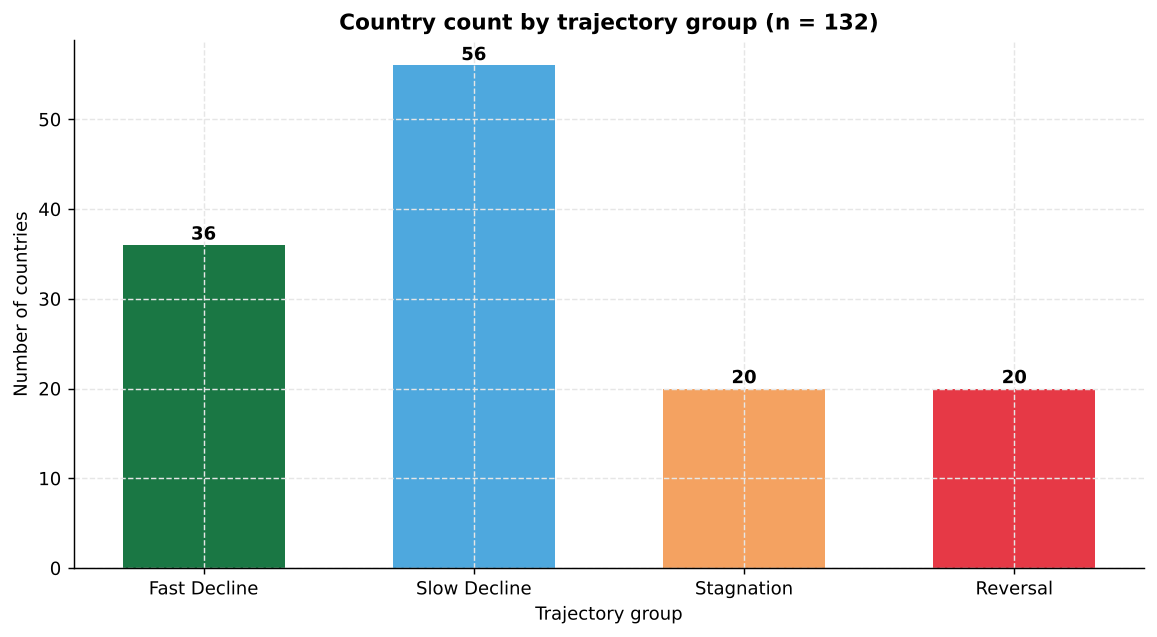

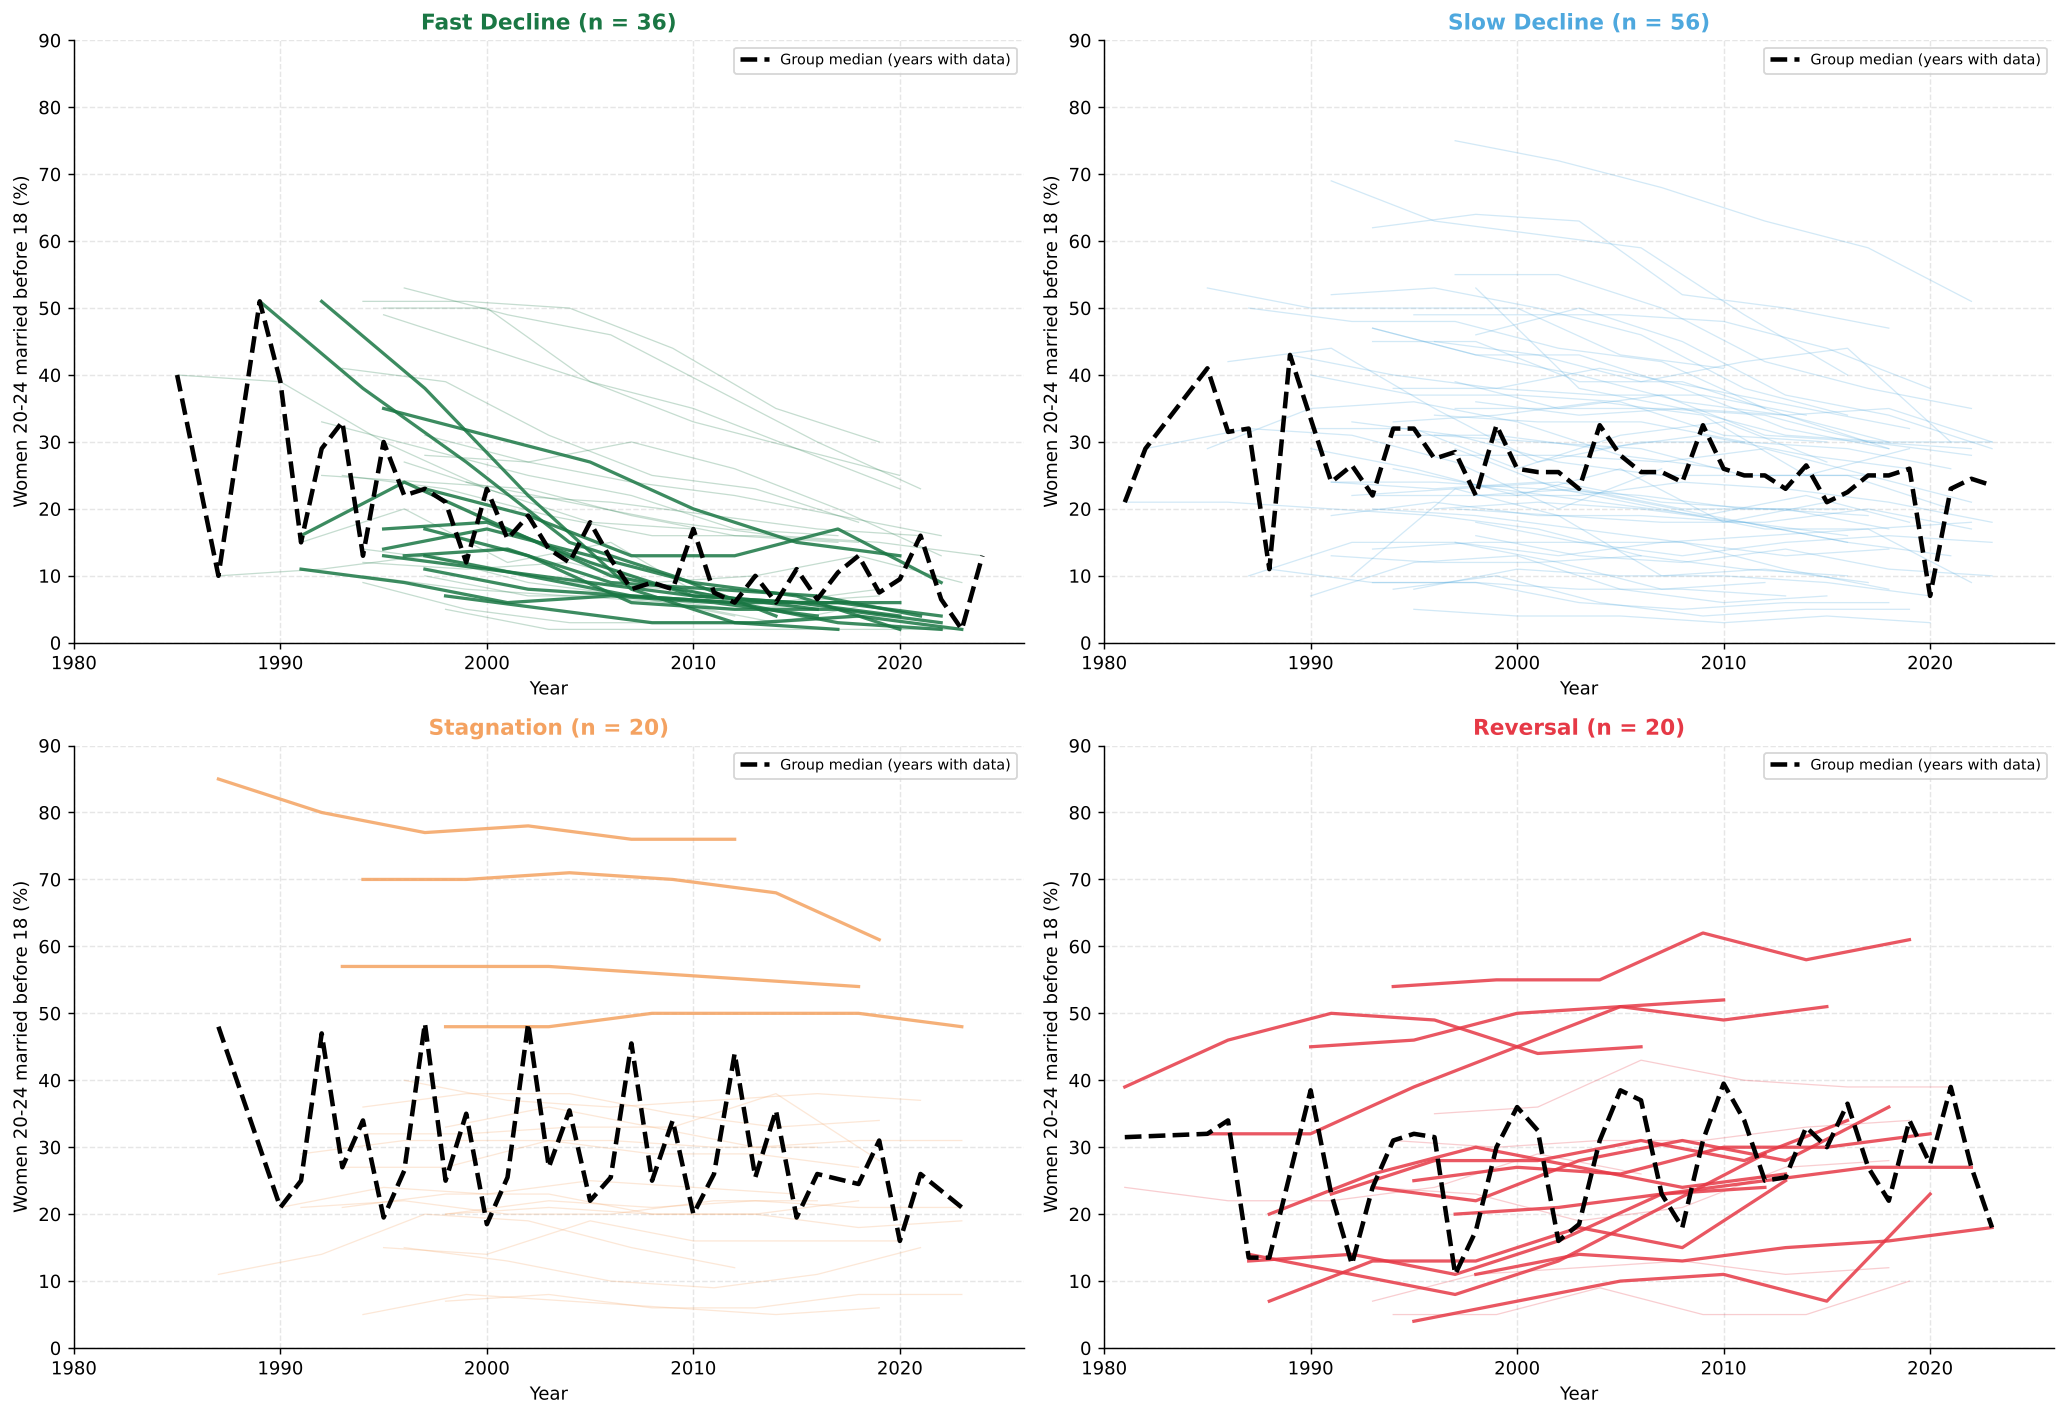

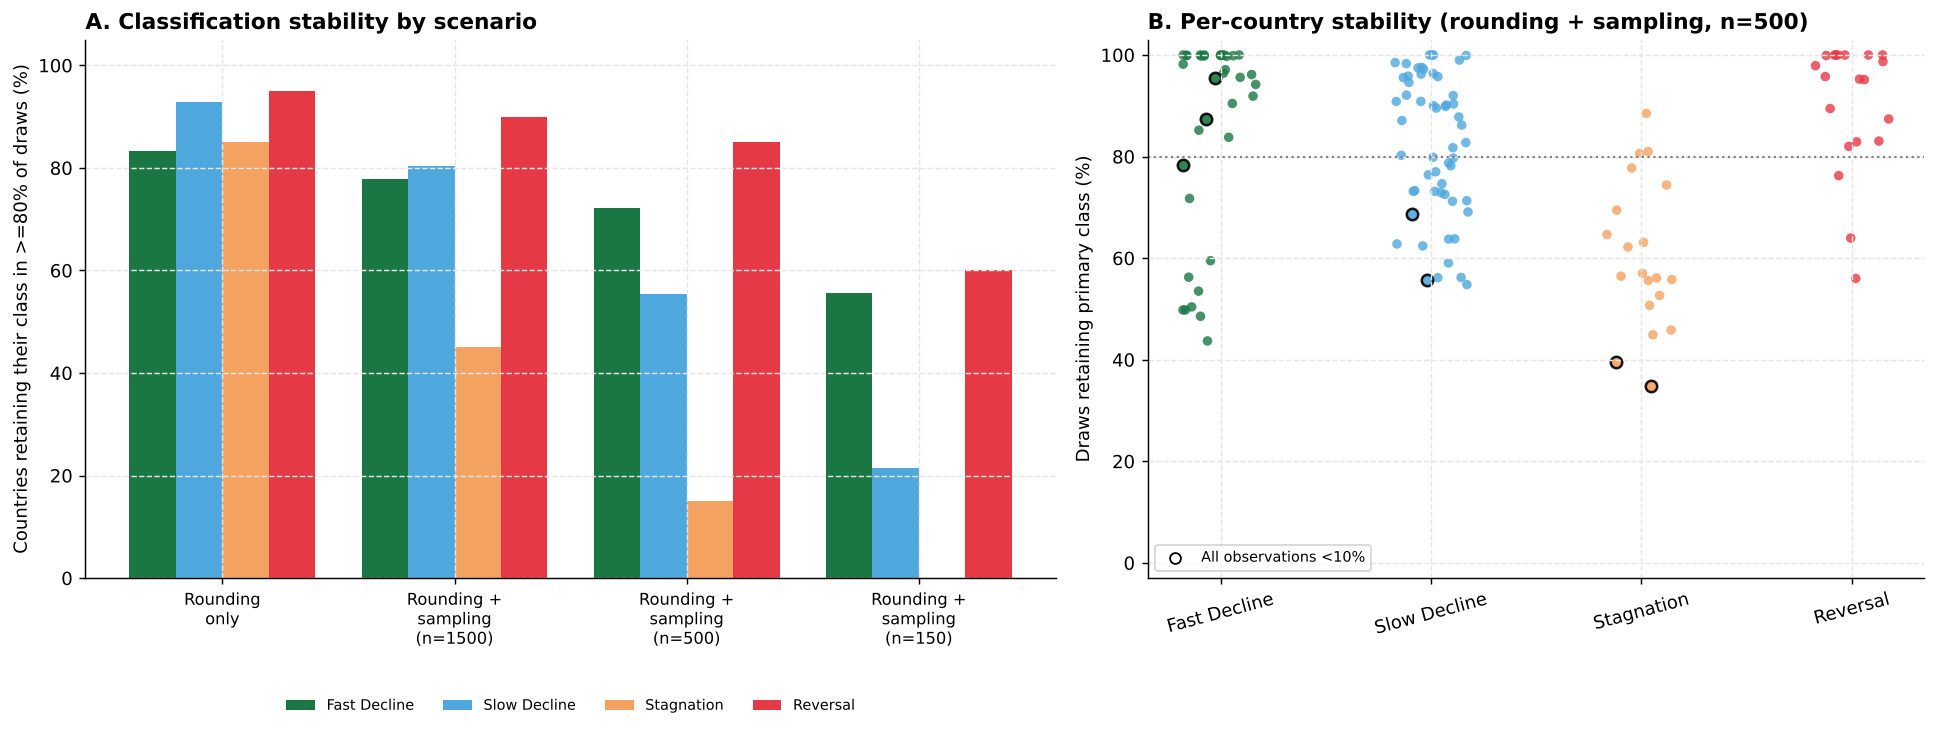

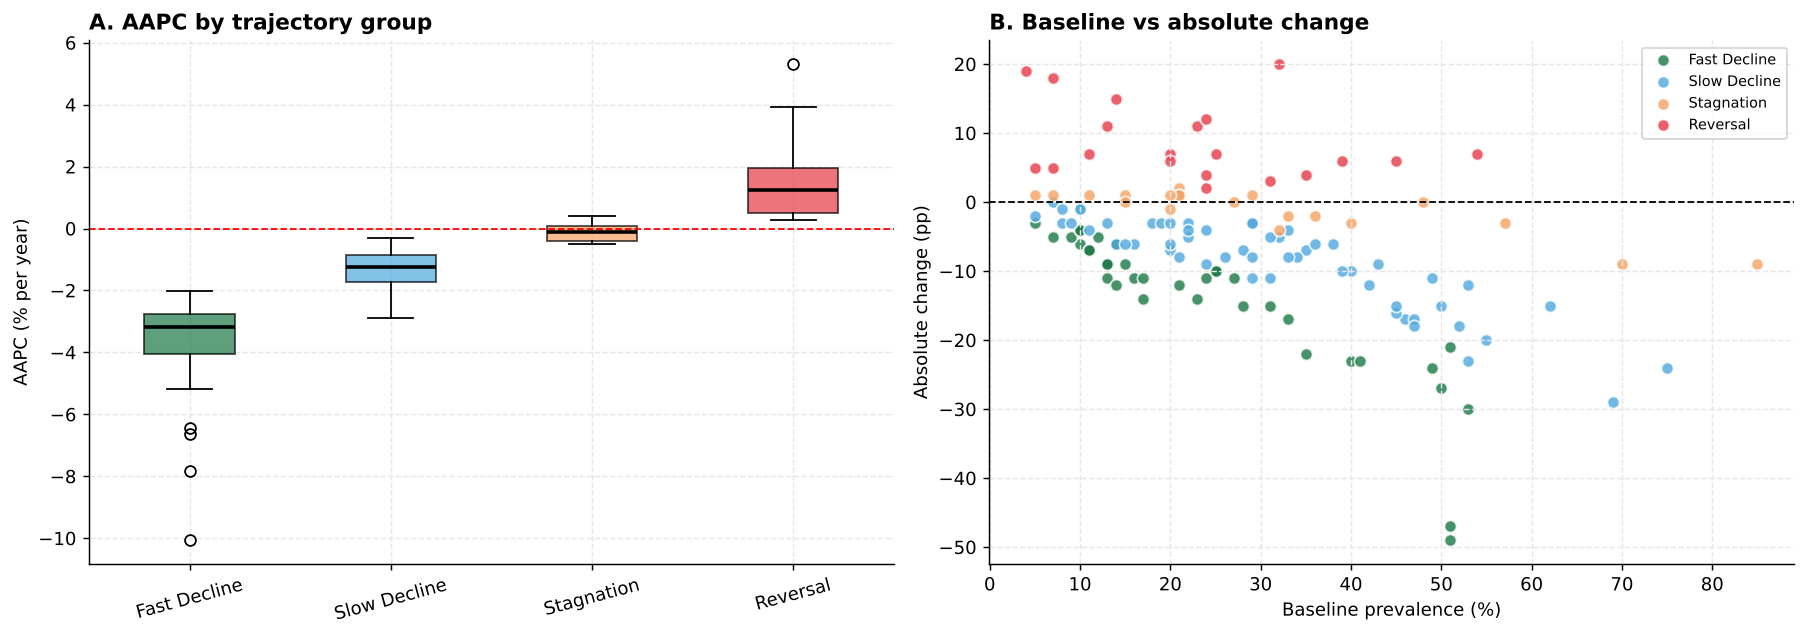

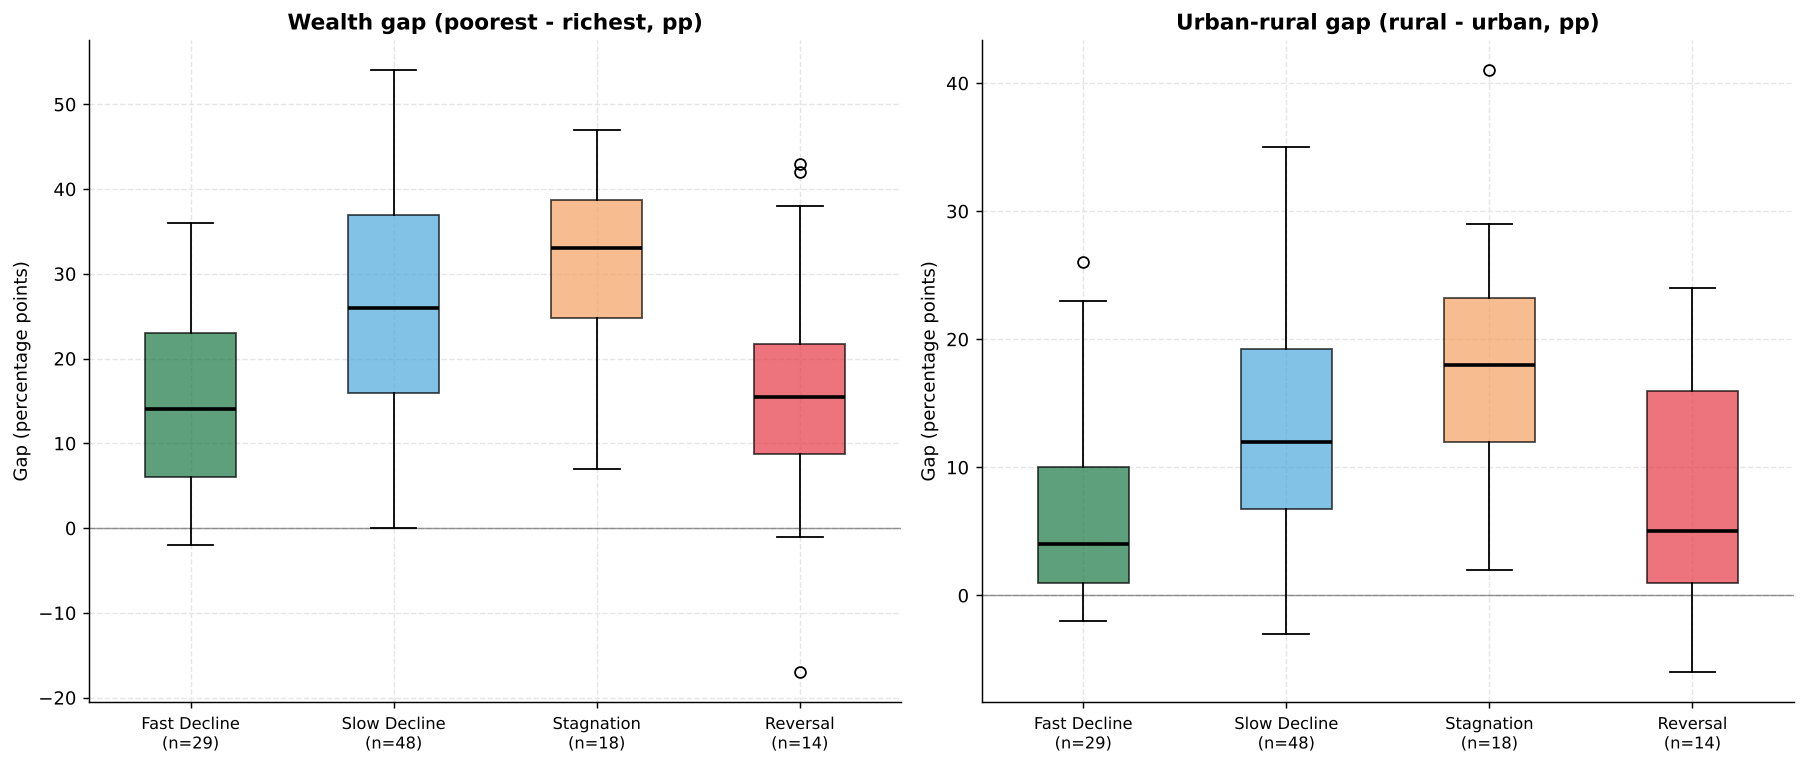

In [11]:
# ───────────────────────── Figures ─────────────────────────────────────────
plt.rcParams.update({'figure.dpi': 130, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.family': 'DejaVu Sans', 'axes.grid': True, 'grid.color': '#E6E6E6',
                     'grid.linestyle': '--'})
# Figure 1 (bar chart, unchanged content)
fig, ax = plt.subplots(figsize=(9, 5))
cnt = S.trajectory.value_counts().reindex(TRAJ_ORDER)
bars = ax.bar(cnt.index, cnt.values, color=[PALETTE[t] for t in TRAJ_ORDER], width=0.6)
for b_, v in zip(bars, cnt.values): ax.text(b_.get_x() + b_.get_width() / 2, v + 0.6, str(v), ha='center', fontweight='bold')
ax.set_ylabel('Number of countries'); ax.set_xlabel('Trajectory group')
ax.set_title('Country count by trajectory group (n = 132)', fontweight='bold')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'Figure1_trajectory_barchart.png'), dpi=200); plt.show()
# Figure 2 spaghetti (unchanged logic)
fig, axes = plt.subplots(2, 2, figsize=(16, 11)); axes = axes.flatten()
for ax, t in zip(axes, TRAJ_ORDER):
    sub = S[S.trajectory == t]
    for _, r in sub.iterrows():
        hi = ((t == 'Reversal' and r.abs_change > 5) or (t == 'Fast Decline' and r.rel_change < -60) or (t == 'Stagnation' and r.baseline > 40))
        ax.plot(r.years, r['values'], color=PALETTE[t], alpha=0.85 if hi else 0.25, lw=1.8 if hi else 0.7)
    med = df_trends[df_trends.iso.isin(sub.iso)].dropna(subset=['prevalence_18']).groupby('year').prevalence_18.median()
    ax.plot(med.index, med.values, 'k--', lw=2.5, label='Group median (years with data)')
    ax.set_title(f'{t} (n = {len(sub)})', color=PALETTE[t], fontweight='bold')
    ax.set_xlabel('Year'); ax.set_ylabel('Women 20-24 married before 18 (%)')
    ax.set_ylim(0, 90); ax.set_xlim(1980, 2026); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'Figure2_spaghetti_trajectories.png'), dpi=200); plt.show()
# New Figure 3: classification stability under measurement uncertainty
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={'width_ratios': [1.25, 1]})
ax = axes[0]
labels_sc = ['Rounding\nonly', 'Rounding +\nsampling\n(n=1500)', 'Rounding +\nsampling\n(n=500)', 'Rounding +\nsampling\n(n=150)']
keys = ['rounding_only', 'neff1500', 'neff500', 'neff150']
w = 0.2
for i, t in enumerate(TRAJ_ORDER):
    vals = [SIM[k]['stable80_by_group'][t] / R['counts_primary'][t] * 100 for k in keys]
    ax.bar(np.arange(4) + (i - 1.5) * w, vals, width=w, color=PALETTE[t], label=t)
ax.set_xticks(range(4)); ax.set_xticklabels(labels_sc, fontsize=9)
ax.set_ylabel('Countries retaining their class in >=80% of draws (%)'); ax.set_ylim(0, 105)
ax.set_title('A. Classification stability by scenario', loc='left', fontweight='bold'); ax.legend(fontsize=8, loc='upper center', ncol=4, bbox_to_anchor=(0.5, -0.2), frameon=False)
ax = axes[1]
for i, t in enumerate(TRAJ_ORDER):
    sub = S[S.trajectory == t]
    jitter = rng.uniform(-0.18, 0.18, len(sub))
    lp = sub.low_prev10.values
    ax.scatter((np.full(len(sub), i) + jitter)[~lp], sub.stab_neff500.values[~lp] * 100, color=PALETTE[t], s=28, alpha=0.8, edgecolor='none')
    ax.scatter((np.full(len(sub), i) + jitter)[lp], sub.stab_neff500.values[lp] * 100, color=PALETTE[t], s=40, alpha=0.9, edgecolor='black', linewidth=1.4)
ax.axhline(80, color='grey', ls=':', lw=1.2)
ax.set_xticks(range(4)); ax.set_xticklabels(TRAJ_ORDER, rotation=15)
ax.set_ylabel('Draws retaining primary class (%)'); ax.set_ylim(-3, 103)
ax.set_title('B. Per-country stability (rounding + sampling, n=500)', loc='left', fontweight='bold')
ax.scatter([], [], facecolor='white', edgecolor='black', label='All observations <10%'); ax.legend(fontsize=8, loc='lower left')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'Figure3_classification_stability.png'), dpi=200); plt.show()
# Fig S1 AAPC distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bp = axes[0].boxplot([S.loc[S.trajectory == t, 'aapc'] for t in TRAJ_ORDER], patch_artist=True, medianprops=dict(color='black', lw=2))
axes[0].set_xticks(range(1, 5)); axes[0].set_xticklabels(TRAJ_ORDER, rotation=15)
for p_, t in zip(bp['boxes'], TRAJ_ORDER): p_.set_facecolor(PALETTE[t]); p_.set_alpha(0.7)
axes[0].axhline(0, color='red', ls='--', lw=1); axes[0].set_ylabel('AAPC (% per year)'); axes[0].set_title('A. AAPC by trajectory group', loc='left', fontweight='bold')
for t in TRAJ_ORDER:
    sub = S[S.trajectory == t]; axes[1].scatter(sub.baseline, sub.abs_change, color=PALETTE[t], label=t, s=45, alpha=0.8, edgecolor='white')
axes[1].axhline(0, color='black', ls='--', lw=1); axes[1].set_xlabel('Baseline prevalence (%)'); axes[1].set_ylabel('Absolute change (pp)')
axes[1].set_title('B. Baseline vs absolute change', loc='left', fontweight='bold'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'FigS1_AAPC_distribution.png'), dpi=200); plt.show()
# Figure H5
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, col, ttl in zip(axes, ['wealth_gap', 'urban_rural_gap'], ['Wealth gap (poorest - richest, pp)', 'Urban-rural gap (rural - urban, pp)']):
    bp = ax.boxplot([G.loc[G.trajectory == t, col] for t in TRAJ_ORDER], patch_artist=True, medianprops=dict(color='black', lw=2))
    ax.set_xticks(range(1, 5)); ax.set_xticklabels([f'{t}\n(n={H5[col]["n_by_group"][t]})' for t in TRAJ_ORDER], fontsize=9)
    for p_, t in zip(bp['boxes'], TRAJ_ORDER): p_.set_facecolor(PALETTE[t]); p_.set_alpha(0.7)
    ax.axhline(0, color='black', lw=0.8, alpha=0.4); ax.set_title(ttl, fontweight='bold'); ax.set_ylabel('Gap (percentage points)')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'Figure_H5_inequality_gradients.png'), dpi=200); plt.show()

## 11. Supplementary Table S1 (LaTeX rows) and exported results

In [12]:
# ───────────────────────── Supplementary Table S1 (LaTeX) ───────────────────
def tex_escape(s): return s.replace('&', '\\&').replace('_', '\\_').replace('%', '\\%')
lines = []
for t in TRAJ_ORDER:
    sub = S[S.trajectory == t].sort_values('country')
    lines.append(f'\\midrule\n\\multicolumn{{9}}{{@{{}}l}}{{\\textbf{{{t}}} ($n$={len(sub)})}} \\\\')
    for _, r in sub.iterrows():
        flags = []
        if r.low_prev10: flags.append('LP')
        if r.single_source: flags.append('SS')
        if r.old_survey: flags.append('OS')
        if r.stab_neff500 < 0.8: flags.append('U')
        name = tex_escape(r.country).replace('Côte', "C\\^{o}te").replace('ã', '\\~{a}').replace('é', "\\'{e}").replace('í', "\\'{i}").replace('ü', '\\"{u}')
        lines.append(f"{name} & {r.iso} & {r.first_year}--{r.last_year} & {r.baseline:.0f} & {r.latest:.0f} & "
                     f"{r.aapc:+.2f} ({r.aapc_lo:+.2f}, {r.aapc_hi:+.2f}) & {r.aapc_end:+.2f} & {r.n_sources} & "
                     f"{r.stab_neff500*100:.0f} {'(' + ','.join(flags) + ')' if flags else ''} \\\\")
open(os.path.join(OUT, 'tableS1_rows.tex'), 'w').write('\n'.join(lines))

S.drop(columns=['years', 'values']).to_csv(os.path.join(OUT, 'Master_results_revision.csv'), index=False)
json.dump(R, open(os.path.join(OUT, 'revision_results.json'), 'w'), indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
print(json.dumps(R, indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o)))

{
 "n_countries": 132,
 "counts_primary": {
  "Fast Decline": 36,
  "Slow Decline": 56,
  "Stagnation": 20,
  "Reversal": 20
 },
 "group_means": {
  "Fast Decline": {
   "n": 36,
   "baseline": 24.3,
   "baseline_sd": 15.0,
   "latest": 9.9,
   "latest_sd": 7.5,
   "abs": -14.4,
   "rel": -59.1,
   "aapc": -3.76,
   "aapc_sd": 1.71
  },
  "Slow Decline": {
   "n": 56,
   "baseline": 31.1,
   "baseline_sd": 16.5,
   "latest": 22.5,
   "latest_sd": 11.2,
   "abs": -8.6,
   "rel": -26.3,
   "aapc": -1.29,
   "aapc_sd": 0.55
  },
  "Stagnation": {
   "n": 20,
   "baseline": 30.6,
   "baseline_sd": 20.8,
   "latest": 29.5,
   "latest_sd": 18.1,
   "abs": -1.2,
   "rel": 0.6,
   "aapc": -0.1,
   "aapc_sd": 0.29
  },
  "Reversal": {
   "n": 20,
   "baseline": 22.8,
   "baseline_sd": 13.6,
   "latest": 31.6,
   "latest_sd": 13.1,
   "abs": 8.8,
   "rel": 75.0,
   "aapc": 1.62,
   "aapc_sd": 1.39
  }
 },
 "audit": {
  "n_obs_counts": {
   "6": 131,
   "5": 1
  },
  "span_counts": {
   "25": 131

## 12. H5b — Relative gaps (poorest/richest and rural/urban ratios)

In [13]:
# ───────────────────────── H5b relative gaps (ratio) ─────────────────────────
G['wealth_ratio'] = G.poorest_18 / G.richest_18.replace(0, np.nan)
G['ur_ratio'] = G.rural_18 / G.urban_18.replace(0, np.nan)
H5b = {}
for col in ['wealth_ratio', 'ur_ratio']:
    gg = G.dropna(subset=[col])
    groups = [gg.loc[gg.trajectory == t, col].values for t in TRAJ_ORDER]
    k = stats.kruskal(*groups)
    H5b[col] = dict(n=len(gg), median={t: round(float(np.median(g_)), 2) for t, g_ in zip(TRAJ_ORDER, groups)},
                    kw_H=round(k.statistic, 2), kw_p=round(k.pvalue, 4))
R['H5_ratio'] = H5b
json.dump(R, open(os.path.join(OUT, 'revision_results.json'), 'w'), indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
print('H5_ratio', H5b)

H5_ratio {'wealth_ratio': {'n': 102, 'median': {'Fast Decline': 4.5, 'Slow Decline': 3.89, 'Stagnation': 3.82, 'Reversal': 1.83}, 'kw_H': np.float64(6.77), 'kw_p': np.float64(0.0798)}, 'ur_ratio': {'n': 109, 'median': {'Fast Decline': 1.78, 'Slow Decline': 1.82, 'Stagnation': 1.81, 'Reversal': 1.32}, 'kw_H': np.float64(6.59), 'kw_p': np.float64(0.0863)}}


## 13. Single-source series vs trajectory

In [14]:
# ───────────────────────── single-source vs trajectory ──────────────────────
ct = pd.crosstab(S.trajectory == 'Reversal', S.single_source)
ct2 = pd.crosstab(S.off_track, S.single_source)
R['single_source_tests'] = dict(
    reversal_vs_rest=dict(table=ct.values.tolist(), fisher=[round(x, 4) for x in stats.fisher_exact(ct.values)]),
    offtrack_vs_ontrack=dict(table=ct2.values.tolist(), fisher=[round(x, 4) for x in stats.fisher_exact(ct2.values)]),
    multi_source_counts=S.loc[~S.single_source, 'trajectory'].value_counts().reindex(TRAJ_ORDER).to_dict(),
    reversal_multi_source=sorted(S.loc[~S.single_source & (S.trajectory == 'Reversal'), 'country']),
)
# reversal countries satisfying all three robustness criteria
S['rev_robust'] = (S.trajectory == 'Reversal') & (S.aapc_lo > 0) & ~S.single_source & ~S.old_survey
R['reversal_all_criteria'] = sorted(S.loc[S.rev_robust, 'country'])
R['reversal_multi_or_recent_and_ci'] = sorted(S.loc[(S.trajectory == 'Reversal') & (S.aapc_lo > 0) & ~S.old_survey, 'country'])
json.dump(R, open(os.path.join(OUT, 'revision_results.json'), 'w'), indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
print('SST', R['single_source_tests'], R['reversal_all_criteria'], R['reversal_multi_or_recent_and_ci'])

SST {'reversal_vs_rest': {'table': [[91, 21], [6, 14]], 'fisher': [np.float64(10.1111), np.float64(0.0)]}, 'offtrack_vs_ontrack': {'table': [[76, 16], [21, 19]], 'fisher': [np.float64(4.2976), np.float64(0.0005)]}, 'multi_source_counts': {'Fast Decline': 30, 'Slow Decline': 46, 'Stagnation': 15, 'Reversal': 6}, 'reversal_multi_source': ['Albania', 'Central African Republic', 'Guyana', 'Iraq', 'Madagascar', 'Zimbabwe']} ['Albania', 'Central African Republic', 'Guyana', 'Iraq'] ['Albania', 'Belize', 'Burkina Faso', 'Central African Republic', 'Guyana', 'Iraq', 'Jamaica', 'Nauru', 'Suriname', 'Tonga', 'Turks and Caicos Islands']
